# UNM ds003490 - Enfoque B: trayectorias funcionales theta-alfa

Este cuaderno construye y caracteriza el **Enfoque B**. Para cada sujeto, canal y banda
se representa la potencia relativa logarítmica de **theta (4-8 Hz)** y **alfa (8-13 Hz)**
como una función del **orden normalizado de las épocas válidas** en el intervalo [0,1].
Parte de las épocas válidas producidas por el cuaderno 01 y su salida
(`enfoque_B_dataset_theta_alpha.npz`) es la entrada del cuaderno de modelado.

El cuaderno:

1. selecciona la complejidad B-spline mediante GCV para theta y alfa;
2. construye las trayectorias funcionales por sujeto y canal;
3. genera las figuras de caracterización de las trayectorias;
4. construye `X_raw` y `X_chol` para el modelado;
5. valida numéricamente la transformación de Cholesky;
6. genera reconstrucciones ilustrativas independientes para theta y alfa.

La FPCA utilizada en las reconstrucciones es descriptiva. En el modelado se ajusta
dentro de cada partición de entrenamiento para evitar fuga de información.

In [11]:
from google.colab import drive
from pathlib import Path

if not Path('/content/drive/MyDrive').exists():
    drive.mount('/content/drive')
else:
    print('Google Drive ya esta montado.')


Google Drive ya esta montado.


In [12]:
# ============================================================================
# CONFIGURACION, IMPORTS Y REPRODUCIBILIDAD
# ============================================================================
from __future__ import annotations

from datetime import datetime, timezone
from pathlib import Path
from typing import Any
import hashlib
import json
import logging
import platform
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
from IPython.display import display
from scipy import linalg
from scipy.integrate import simpson
from scipy.signal import welch
from sklearn.decomposition import PCA
from sklearn.preprocessing import SplineTransformer

# ---------------------------------------------------------------------------
# Logging
# ---------------------------------------------------------------------------
logging.basicConfig(
    level=logging.INFO,
    format='%(asctime)s | %(levelname)s | %(message)s',
    datefmt='%H:%M:%S',
    force=True,
)
LOGGER = logging.getLogger('enfoque_B_theta_alpha')

# ---------------------------------------------------------------------------
# Semilla y rutas
# ---------------------------------------------------------------------------
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

FINAL_ROOT = Path('/content/drive/MyDrive/tesis_parkinson/resultados')
PREPROC_DIR = FINAL_ROOT / '01_preprocesamiento'
MANIFEST = PREPROC_DIR / 'epochs_manifest.csv'

RUN_ID = 'theta_alpha'
OUT_DIR = FINAL_ROOT / '02B_enfoque_B'
FIG_DIR = OUT_DIR / 'figuras'
FIG_TESIS_DIR = FIG_DIR / 'tesis'
FIG_AUX_DIR = FIG_DIR / 'auxiliares'
for _d in (OUT_DIR, FIG_DIR, FIG_TESIS_DIR, FIG_AUX_DIR):
    _d.mkdir(parents=True, exist_ok=True)

DATASET_PATH = OUT_DIR / f'enfoque_B_dataset_{RUN_ID}.npz'
METADATA_PATH = OUT_DIR / f'enfoque_B_dataset_{RUN_ID}_metadata.json'

# ---------------------------------------------------------------------------
# Parametros espectrales y funcionales
# ---------------------------------------------------------------------------
PSD_FMIN, PSD_FMAX = 1.0, 40.0
NORM_FMIN, NORM_FMAX = 1.0, 30.0
WELCH_SEC, WELCH_OVL = 2.0, 0.5
EPS = 1e-20

# El orden de insercion se conserva en el archivo de salida.
BANDS_DEF: dict[str, tuple[float, float]] = {
    'theta': (4.0, 8.0),
    'alpha': (8.0, 13.0),
}

EXPECTED_CHANNELS = (
    'C3', 'Cz', 'C4', 'P7', 'P8', 'P3', 'Pz', 'P4', 'O1', 'O2'
)
CHANNEL = 'Pz'
BAND_MAIN = 'alpha'
BAND_DISPLAY = {'theta': 'theta', 'alpha': 'alfa'}
MIN_EPOCHS = 6

BSPLINE_DEGREE = 3
BSPLINE_RIDGE = 1e-6
MIN_GCV_KNOTS = 2
MAX_GCV_KNOTS = 8

# La grilla de figuras no se usa para estimar los coeficientes del modelo.
N_PLOT_GRID = 101
# Grilla independiente y densa para integrar la matriz de Gram.
N_GRAM_GRID = 1001
# Grilla comun para fijar los limites y nudos uniformes de SplineTransformer.
SPLINE_REFERENCE_GRID = np.linspace(0.0, 1.0, 1001)

STRICT_COHORT_CHECK = True
EXPECTED_N_SUBJECTS = 48
EXPECTED_CLASS_COUNTS = {0: 24, 1: 24}

LOGGER.info(
    'Enfoque B | bandas=%s | canal de figuras=%s | salida=%s',
    list(BANDS_DEF), CHANNEL, DATASET_PATH,
)


22:24:57 | INFO | Enfoque B | bandas=['theta', 'alpha'] | canal de figuras=Pz | salida=/content/drive/MyDrive/tesis_parkinson/resultados/02B_enfoque_B/enfoque_B_dataset_theta_alpha.npz


## 1. Carga de la cohorte y cálculo de theta/alfa por época

Se utilizan únicamente los 48 sujetos resultantes del control de calidad del cuaderno 01
(24 HC y 24 PD_OFF) y los 10 canales seleccionados. La potencia de cada banda se normaliza
respecto a la potencia total entre 1 y 30 Hz y se transforma con logaritmo en base 10.

In [13]:
# ============================================================================
# CARGA DEL MANIFEST Y FUNCIONES ESPECTRALES
# ============================================================================
REQUIRED_MANIFEST_COLUMNS = {
    'subject_id', 'condition', 'file', 'sfreq', 'ch_names',
    'n_epocas_conservadas', 'error',
}

if not MANIFEST.exists():
    raise FileNotFoundError(f'No se encontro el manifest: {MANIFEST}')

man = pd.read_csv(MANIFEST)
missing_columns = REQUIRED_MANIFEST_COLUMNS.difference(man.columns)
if missing_columns:
    raise ValueError(f'Faltan columnas en el manifest: {sorted(missing_columns)}')

man['error'] = man['error'].fillna('').astype(str)
man = man[
    (man['error'] == '')
    & (man['n_epocas_conservadas'] >= MIN_EPOCHS)
    & (man['condition'].isin(['CTL', 'PD_OFF']))
].copy()
man['label'] = man['condition'].map({'CTL': 0, 'PD_OFF': 1}).astype(int)
man['subject_id'] = man['subject_id'].astype(str)
man = man.sort_values(['subject_id', 'condition']).reset_index(drop=True)

if not man['subject_id'].is_unique:
    duplicated = man.loc[
        man['subject_id'].duplicated(keep=False),
        ['subject_id', 'condition', 'file'],
    ]
    raise ValueError(f'Hay identificadores de sujeto duplicados:\n{duplicated}')

class_counts = man['label'].value_counts().sort_index().to_dict()
LOGGER.info(
    'Sujetos incluidos=%d | HC=%d | PD_OFF=%d',
    len(man), class_counts.get(0, 0), class_counts.get(1, 0),
)

if STRICT_COHORT_CHECK:
    if len(man) != EXPECTED_N_SUBJECTS:
        raise AssertionError(
            f'Se esperaban {EXPECTED_N_SUBJECTS} sujetos y se encontraron {len(man)}.'
        )
    if class_counts != EXPECTED_CLASS_COUNTS:
        raise AssertionError(
            f'Distribucion de clases inesperada: {class_counts}; '
            f'esperada: {EXPECTED_CLASS_COUNTS}.'
        )


def parse_channel_names(value: Any) -> list[str]:
    """Convierte la columna ch_names del manifest en una lista limpia."""
    if not isinstance(value, str) or not value.strip():
        raise ValueError(f'ch_names invalido: {value!r}')
    return [name.strip() for name in value.split(',') if name.strip()]


def reorder_to_expected_channels(
    data_uv: np.ndarray,
    channel_names: list[str],
    subject_id: str,
) -> tuple[np.ndarray, list[str]]:
    """Reordena el eje de canales y verifica que no falte ninguna derivacion."""
    if data_uv.ndim != 3:
        raise ValueError(
            f'{subject_id}: se esperaba (epocas, canales, muestras), '
            f'recibido {data_uv.shape}.'
        )
    if data_uv.shape[1] != len(channel_names):
        raise ValueError(
            f'{subject_id}: el array tiene {data_uv.shape[1]} canales, '
            f'pero el manifest contiene {len(channel_names)} nombres.'
        )

    missing = [ch for ch in EXPECTED_CHANNELS if ch not in channel_names]
    if missing:
        raise ValueError(f'{subject_id}: faltan canales requeridos: {missing}')

    indices = [channel_names.index(ch) for ch in EXPECTED_CHANNELS]
    reordered = data_uv[:, indices, :]
    return reordered, list(EXPECTED_CHANNELS)


def psd_linear_epochs(
    data_uv: np.ndarray,
    sfreq: float,
) -> tuple[np.ndarray, np.ndarray]:
    """PSD lineal por epoca y canal, en uV^2/Hz, mediante Welch."""
    if sfreq <= 0:
        raise ValueError(f'Frecuencia de muestreo invalida: {sfreq}')
    if not np.isfinite(data_uv).all():
        raise ValueError('El EEG contiene NaN o valores infinitos.')

    nperseg = min(int(round(sfreq * WELCH_SEC)), data_uv.shape[-1])
    noverlap = int(round(nperseg * WELCH_OVL))
    if noverlap >= nperseg:
        noverlap = nperseg - 1

    freqs, psd = welch(
        data_uv,
        fs=sfreq,
        window='hann',
        nperseg=nperseg,
        noverlap=noverlap,
        detrend='constant',
        scaling='density',
        axis=-1,
    )
    mask = (freqs >= PSD_FMIN) & (freqs <= PSD_FMAX)
    return psd[..., mask], freqs[mask]


def band_power_per_epoch(
    psd_lin: np.ndarray,
    freqs: np.ndarray,
    band_min: float,
    band_max: float,
    norm_min: float = NORM_FMIN,
    norm_max: float = NORM_FMAX,
) -> np.ndarray:
    """Potencia relativa por epoca-canal: banda / potencia total 1-30 Hz."""
    band_mask = (freqs >= band_min) & (freqs <= band_max)
    norm_mask = (freqs >= norm_min) & (freqs <= norm_max)

    if band_mask.sum() < 2:
        raise ValueError(
            f'La banda [{band_min}, {band_max}] contiene menos de dos bins.'
        )
    if norm_mask.sum() < 2:
        raise ValueError('La banda de normalizacion contiene menos de dos bins.')

    band_power = simpson(
        psd_lin[..., band_mask],
        x=freqs[band_mask],
        axis=-1,
    )
    total_power = simpson(
        psd_lin[..., norm_mask],
        x=freqs[norm_mask],
        axis=-1,
    )
    total_power = np.clip(total_power, EPS, None)
    return band_power / total_power


# ---------------------------------------------------------------------------
# Carga por sujeto
# ---------------------------------------------------------------------------
per_subj: list[dict[str, Any]] = []
for _, row in man.iterrows():
    subject_id = str(row['subject_id'])
    data_path = Path(str(row['file']))
    if not data_path.exists():
        raise FileNotFoundError(f'{subject_id}: no existe {data_path}')

    data_uv = np.load(data_path, allow_pickle=False).astype(np.float64, copy=False)
    channel_names = parse_channel_names(row['ch_names'])
    data_uv, channel_names = reorder_to_expected_channels(
        data_uv, channel_names, subject_id,
    )

    if data_uv.shape[0] < MIN_EPOCHS:
        raise ValueError(
            f'{subject_id}: solo tiene {data_uv.shape[0]} epocas; '
            f'minimo requerido={MIN_EPOCHS}.'
        )

    psd_lin, freqs = psd_linear_epochs(data_uv, float(row['sfreq']))
    power_by_band: dict[str, np.ndarray] = {}
    for band, (low, high) in BANDS_DEF.items():
        relative_power = band_power_per_epoch(
            psd_lin, freqs, low, high,
        )
        log_relative_power = np.log10(np.clip(relative_power, EPS, None))
        if not np.isfinite(log_relative_power).all():
            raise ValueError(f'{subject_id}: valores no finitos en banda {band}.')
        power_by_band[band] = log_relative_power

    per_subj.append({
        'subject_id': subject_id,
        'condition': str(row['condition']),
        'label': int(row['label']),
        'power': power_by_band,
        'n_ep': int(psd_lin.shape[0]),
        'ch_names': channel_names,
    })

subject_ids = np.asarray([s['subject_id'] for s in per_subj], dtype=str)
y_subject = np.asarray([s['label'] for s in per_subj], dtype=np.int64)
n_epochs_subject = np.asarray([s['n_ep'] for s in per_subj], dtype=np.int64)
ch_ref = list(EXPECTED_CHANNELS)
PZ = ch_ref.index(CHANNEL)  # indice del canal Pz para metricas/figuras auxiliares

assert len(np.unique(subject_ids)) == len(subject_ids)
assert all(s['ch_names'] == ch_ref for s in per_subj)
LOGGER.info(
    'Carga completa | sujetos=%d | canales=%d | epocas min/mediana/max=%d/%.1f/%d',
    len(per_subj), len(ch_ref), int(n_epochs_subject.min()),
    float(np.median(n_epochs_subject)), int(n_epochs_subject.max()),
)


22:24:58 | INFO | Sujetos incluidos=48 | HC=24 | PD_OFF=24
22:25:21 | INFO | Carga completa | sujetos=48 | canales=10 | epocas min/mediana/max=10/15.0/50


## 2. Selección de la complejidad B-spline mediante GCV

El GCV se calcula sobre todas las trayectorias sujeto-canal de cada banda. Theta y
alfa se muestran en una **misma gráfica** para facilitar la comparación, manteniendo
la selección independiente de la complejidad de cada banda.


22:25:21 | INFO | Rango GCV comun=[2, 3, 4, 5, 6, 7] | minimo de epocas=10


k optimo por banda (GCV):
  theta   : k=2 (4 funciones base)
  alpha   : k=2 (4 funciones base)

[INTERPRETACION] El minimo esta en el borde inferior para ['theta', 'alpha']. Esto favorece la representacion de menor complejidad del rango evaluado y sugiere que predominan el nivel y las tendencias de bajo orden. No demuestra que las trayectorias sean constantes.


banda,alpha,theta
k,,
2,0.022295,0.028919
3,0.023637,0.031500
4,0.025636,0.034709
5,0.029265,0.039277
6,0.034267,0.047012
7,0.041410,0.057291


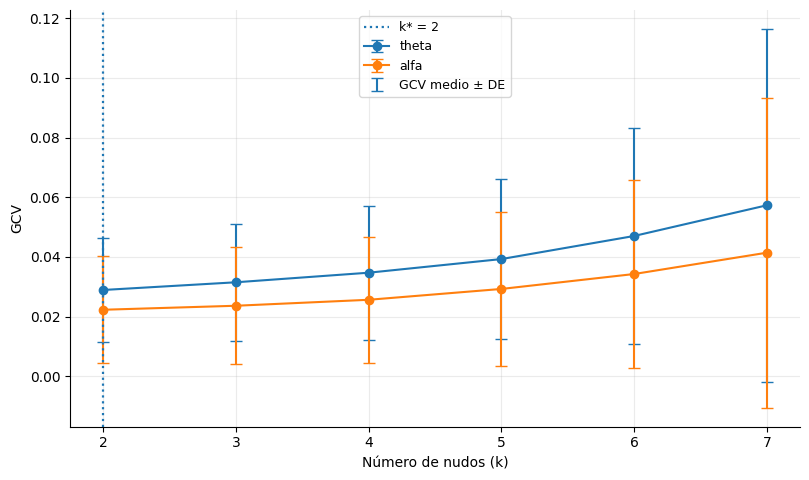

22:25:24 | INFO | GCV guardado en /content/drive/MyDrive/tesis_parkinson/resultados/02B_enfoque_B/gcv_enfoque_B_theta_alpha.csv


Figura guardada: /content/drive/MyDrive/tesis_parkinson/resultados/02B_enfoque_B/figuras/tesis/gcv_enfoque_B_theta_alfa.png


In [14]:
# ============================================================================
# GCV SOBRE TODAS LAS TRAYECTORIAS
# ============================================================================
def make_spline_transformer(n_knots: int) -> SplineTransformer:
    """Crea una base comun en [0,1] con nudos uniformes."""
    transformer = SplineTransformer(
        n_knots=n_knots,
        degree=BSPLINE_DEGREE,
        knots='uniform',
        include_bias=True,
        extrapolation='constant',
    )
    transformer.fit(SPLINE_REFERENCE_GRID.reshape(-1, 1))
    return transformer


def solve_ridge_coefficients(
    design: np.ndarray,
    values: np.ndarray,
    ridge: float = BSPLINE_RIDGE,
) -> np.ndarray:
    """Ajusta coeficientes por crestas; admite y=(n,) o y=(n,p)."""
    n_basis = design.shape[1]
    system = design.T @ design + ridge * np.eye(n_basis)
    rhs = design.T @ values
    return linalg.solve(
        system,
        rhs,
        assume_a='pos',
        check_finite=True,
    )


def bspline_gcv(
    x: np.ndarray,
    y_values: np.ndarray,
    transformer: SplineTransformer,
    ridge: float = BSPLINE_RIDGE,
) -> float:
    """GCV de una trayectoria para una base B-spline ya fijada."""
    design = transformer.transform(x.reshape(-1, 1))
    n_obs, n_basis = design.shape
    if n_basis >= n_obs:
        return np.inf

    system = design.T @ design + ridge * np.eye(n_basis)
    coefficients = linalg.solve(
        system,
        design.T @ y_values,
        assume_a='pos',
        check_finite=True,
    )
    fitted = design @ coefficients
    mse = float(np.mean((y_values - fitted) ** 2))

    # tr(H) = tr[(B'B + lambda I)^-1 B'B]
    effective_df = float(np.trace(linalg.solve(
        system,
        design.T @ design,
        assume_a='pos',
        check_finite=True,
    )))
    denominator = (1.0 - effective_df / n_obs) ** 2
    return np.inf if denominator <= 1e-12 else mse / denominator


min_n_epochs = int(n_epochs_subject.min())
# n_basis = n_knots + degree - 1 y se exige n_basis < n_epocas.
max_admissible_knots = min(
    MAX_GCV_KNOTS,
    min_n_epochs - BSPLINE_DEGREE,
)
if max_admissible_knots < MIN_GCV_KNOTS:
    raise ValueError(
        'No hay suficientes epocas para ajustar el B-spline cubico mas simple.'
    )

K_RANGE_B = list(range(MIN_GCV_KNOTS, max_admissible_knots + 1))
spline_by_k = {k: make_spline_transformer(k) for k in K_RANGE_B}
LOGGER.info('Rango GCV comun=%s | minimo de epocas=%d', K_RANGE_B, min_n_epochs)

K_OPT_BAND: dict[str, int] = {}
gcv_rows: list[dict[str, Any]] = []

for band in BANDS_DEF:
    trajectories: list[tuple[np.ndarray, np.ndarray]] = []
    for subject in per_subj:
        power = subject['power'][band]
        n_epochs, n_channels = power.shape
        t_subject = np.linspace(0.0, 1.0, n_epochs)
        for channel_idx in range(n_channels):
            trajectories.append((t_subject, power[:, channel_idx]))

    expected_n = len(trajectories)
    for n_knots in K_RANGE_B:
        transformer = spline_by_k[n_knots]
        values = np.asarray([
            bspline_gcv(t_subject, trajectory, transformer)
            for t_subject, trajectory in trajectories
        ], dtype=float)

        if len(values) != expected_n or not np.isfinite(values).all():
            raise RuntimeError(
                f'GCV invalido en {band}, k={n_knots}: '
                f'{np.isfinite(values).sum()}/{expected_n} valores finitos.'
            )

        gcv_rows.append({
            'banda': band,
            'k': int(n_knots),
            'n_bases': int(n_knots + BSPLINE_DEGREE - 1),
            'gcv_medio': float(values.mean()),
            'gcv_mediana': float(np.median(values)),
            'gcv_sd': float(values.std(ddof=1)),
            'n_usadas': int(len(values)),
        })

    band_table = pd.DataFrame(
        row for row in gcv_rows if row['banda'] == band
    )
    best_index = band_table['gcv_medio'].idxmin()
    K_OPT_BAND[band] = int(band_table.loc[best_index, 'k'])


gcv_tab = pd.DataFrame(gcv_rows)
if gcv_tab.groupby('banda')['n_usadas'].nunique().max() != 1:
    raise AssertionError('El numero de trayectorias GCV cambia entre valores de k.')

print('k optimo por banda (GCV):')
for band in BANDS_DEF:
    n_knots = K_OPT_BAND[band]
    n_basis = n_knots + BSPLINE_DEGREE - 1
    print(f'  {band:8s}: k={n_knots} ({n_basis} funciones base)')

bands_at_floor = [
    band for band, n_knots in K_OPT_BAND.items()
    if n_knots == MIN_GCV_KNOTS
]
if bands_at_floor:
    print(
        '\n[INTERPRETACION] El minimo esta en el borde inferior para '
        f'{bands_at_floor}. Esto favorece la representacion de menor complejidad '
        'del rango evaluado y sugiere que predominan el nivel y las tendencias '
        'de bajo orden. No demuestra que las trayectorias sean constantes.'
    )

display(
    gcv_tab.pivot(index='k', columns='banda', values='gcv_medio').round(6)
)
gcv_path = OUT_DIR / f'gcv_enfoque_B_{RUN_ID}.csv'
gcv_tab.to_csv(gcv_path, index=False)

# Figura de GCV: theta y alfa en una sola gráfica.
fig, ax = plt.subplots(figsize=(8.2, 4.9))
band_colors = {'theta': '#1f77b4', 'alpha': '#ff7f0e'}

for band in BANDS_DEF:
    subset = gcv_tab[gcv_tab['banda'] == band].sort_values('k')
    ax.errorbar(
        subset['k'], subset['gcv_medio'], yerr=subset['gcv_sd'],
        marker='o', linewidth=1.5, capsize=4,
        color=band_colors[band], label=BAND_DISPLAY[band],
    )

unique_k = sorted(set(K_OPT_BAND.values()))
if len(unique_k) == 1:
    ax.axvline(unique_k[0], linestyle=':', linewidth=1.6,
               label=f'k* = {unique_k[0]}')
else:
    for band in BANDS_DEF:
        ax.axvline(
            K_OPT_BAND[band], linestyle=':', linewidth=1.3,
            color=band_colors[band],
            label=f'k* {BAND_DISPLAY[band]} = {K_OPT_BAND[band]}',
        )

# Entrada visual que aclara que las barras corresponden a ±1 DE.
ax.errorbar([np.nan], [np.nan], yerr=[0.01], fmt='none', capsize=4,
            label='GCV medio ± DE')
ax.set_xlabel('Número de nudos (k)')
ax.set_ylabel('GCV')
ax.spines[['top', 'right']].set_visible(False)
ax.grid(alpha=0.25)
ax.legend(fontsize=9, frameon=True)
fig.tight_layout()
gcv_figure_path = FIG_TESIS_DIR / 'gcv_enfoque_B_theta_alfa.png'
fig.savefig(gcv_figure_path, dpi=220, bbox_inches='tight')
plt.show()
LOGGER.info('GCV guardado en %s', gcv_path)
print('Figura guardada:', gcv_figure_path)


## 3. Construcción de las trayectorias funcionales

Cada sujeto conserva su número real de épocas. El dominio se normaliza a [0,1] y la
base se evalúa sobre las posiciones observadas de cada registro. La malla común solo
se utiliza para caracterización y visualización.


In [15]:
# ============================================================================
# TRAYECTORIAS CRUDAS Y FUNCIONALES PARA CARACTERIZACION
# ============================================================================
OPT_SPLINES = {
    band: make_spline_transformer(K_OPT_BAND[band])
    for band in BANDS_DEF
}


def fit_trajectory(
    transformer: SplineTransformer,
    t_subject: np.ndarray,
    values: np.ndarray,
    t_output: np.ndarray,
) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Ajusta una o varias trayectorias con una base comun.

    Parameters
    ----------
    values:
        (n_epocas,) o (n_epocas, n_canales).

    Returns
    -------
    coefficients:
        (n_bases,) o (n_canales, n_bases).
    fitted_output:
        En `t_output`.
    fitted_subject:
        En los puntos originales `t_subject`.
    """
    design_subject = transformer.transform(t_subject.reshape(-1, 1))
    coefficient_columns = solve_ridge_coefficients(design_subject, values)
    design_output = transformer.transform(t_output.reshape(-1, 1))

    if values.ndim == 1:
        coefficients = coefficient_columns
        fitted_output = design_output @ coefficients
        fitted_subject = design_subject @ coefficients
    else:
        coefficients = coefficient_columns.T
        fitted_output = coefficients @ design_output.T
        fitted_subject = coefficients @ design_subject.T

    return coefficients, fitted_output, fitted_subject


t_grid = np.linspace(0.0, 1.0, N_PLOT_GRID)
traj_func = {band: {0: [], 1: []} for band in BANDS_DEF}
traj_crude = {band: {0: [], 1: []} for band in BANDS_DEF}
verification_records: list[dict[str, Any]] = []

for subject in per_subj:
    label = subject['label']
    n_epochs = subject['n_ep']
    t_subject = np.linspace(0.0, 1.0, n_epochs)

    for band in BANDS_DEF:
        power = subject['power'][band]
        _, fitted_grid, fitted_subject = fit_trajectory(
            OPT_SPLINES[band], t_subject, power, t_grid,
        )
        crude_grid = np.stack([
            np.interp(t_grid, t_subject, power[:, channel_idx])
            for channel_idx in range(power.shape[1])
        ])

        traj_func[band][label].append(fitted_grid)
        traj_crude[band][label].append(crude_grid)

        for channel_idx, channel_name in enumerate(ch_ref):
            verification_records.append({
                'subject_id': subject['subject_id'],
                'label': int(label),
                'condition': subject['condition'],
                'band': band,
                'channel': channel_name,
                't': t_subject.copy(),
                'raw': power[:, channel_idx].copy(),
                'fit': fitted_subject[channel_idx].copy(),
            })

for band in BANDS_DEF:
    for label in (0, 1):
        traj_func[band][label] = np.stack(traj_func[band][label])
        traj_crude[band][label] = np.stack(traj_crude[band][label])

LOGGER.info(
    'Trayectorias construidas | grilla figuras=%d | k=%s',
    N_PLOT_GRID, K_OPT_BAND,
)


22:25:24 | INFO | Trayectorias construidas | grilla figuras=101 | k={'theta': 2, 'alpha': 2}


## 4. Representaciones funcionales theta y alfa

Para cada banda se genera una figura con HC y PD_OFF en la fila superior y la comparación de
medias en la fila inferior. Los títulos muestran explícitamente `n=24 × 10 canales`. Las curvas
grises representan las trayectorias funcionales sujeto-canal y la línea gruesa la media funcional.

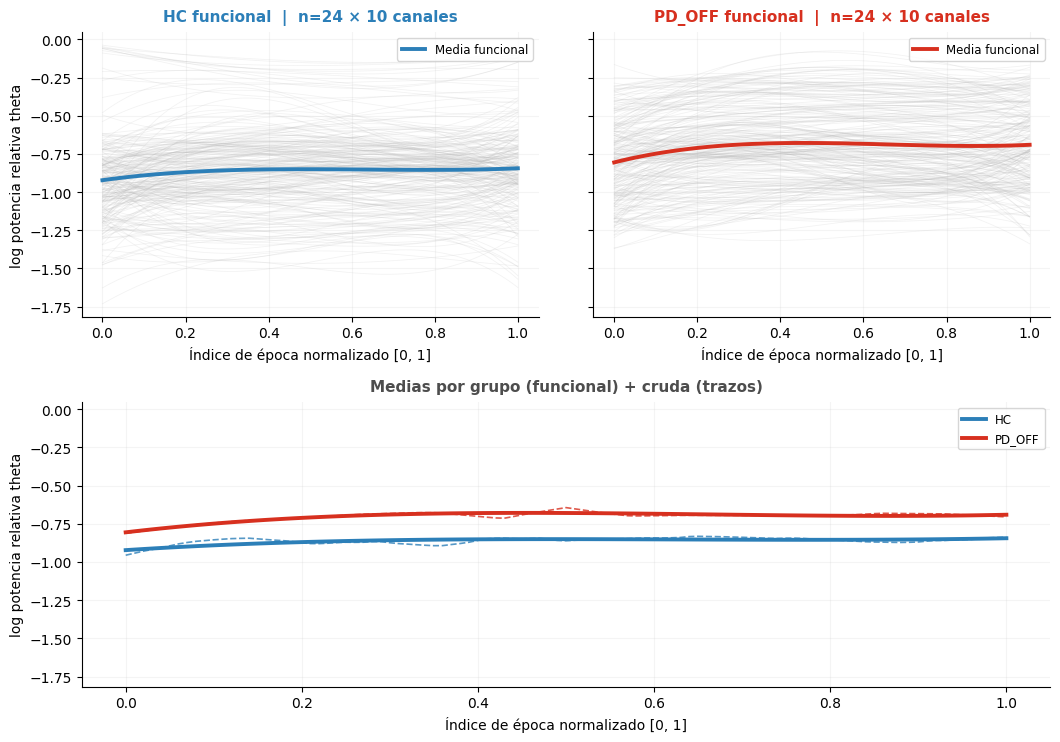

Figura guardada (theta): /content/drive/MyDrive/tesis_parkinson/resultados/02B_enfoque_B/figuras/tesis/curvas_funcionales_B_theta.png


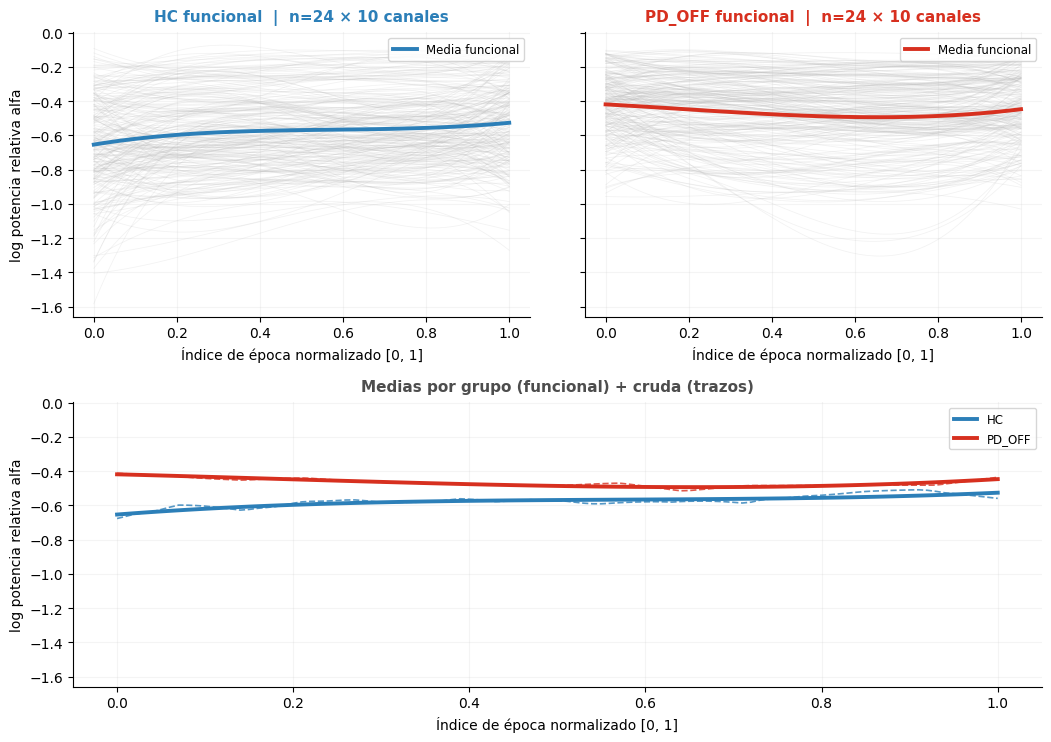

Figura guardada (alfa): /content/drive/MyDrive/tesis_parkinson/resultados/02B_enfoque_B/figuras/tesis/curvas_funcionales_B_alfa.png


In [16]:
# ============================================================================
# FIGURAS DE REPRESENTACIONES FUNCIONALES THETA Y ALFA
# ============================================================================
COL = {0: '#2C7FB8', 1: '#D7301F'}
NAME = {0: 'HC', 1: 'PD_OFF'}
n_channels = len(ch_ref)


def _band_arrays(band: str):
    functional = {
        lab: traj_func[band][lab].reshape(-1, traj_func[band][lab].shape[-1])
        for lab in (0, 1)
    }
    crude = {
        lab: traj_crude[band][lab].reshape(-1, traj_crude[band][lab].shape[-1])
        for lab in (0, 1)
    }
    n_subjects = {lab: traj_func[band][lab].shape[0] for lab in (0, 1)}
    return functional, crude, n_subjects


def _draw_group_panel(ax, band: str, lab: int, functional, n_subjects) -> None:
    for curve in functional[lab]:
        ax.plot(t_grid, curve, color='0.72', alpha=0.18, linewidth=0.55)
    ax.plot(
        t_grid, functional[lab].mean(axis=0), color=COL[lab], linewidth=2.8,
        label='Media funcional',
    )
    ax.set_title(
        f'{NAME[lab]} funcional  |  n={n_subjects[lab]} × {n_channels} canales',
        color=COL[lab], fontsize=11, fontweight='bold', pad=8,
    )
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(alpha=0.13)
    ax.legend(loc='upper right', fontsize=8.5, frameon=True)


def _draw_mean_panel(ax, band: str, functional, crude) -> None:
    for lab in (0, 1):
        ax.plot(
            t_grid, functional[lab].mean(axis=0), color=COL[lab], linewidth=2.8,
            label=NAME[lab],
        )
        ax.plot(
            t_grid, crude[lab].mean(axis=0), color=COL[lab], linewidth=1.2,
            linestyle='--', alpha=0.80,
        )
    ax.set_title(
        'Medias por grupo (funcional) + cruda (trazos)',
        color='0.30', fontsize=11, fontweight='bold', pad=8,
    )
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(alpha=0.13)
    ax.legend(loc='upper right', fontsize=8.5, frameon=True)


def plot_band_representation(band: str) -> Path:
    functional, crude, n_subjects = _band_arrays(band)
    band_es = BAND_DISPLAY[band]
    ylabel = f'log potencia relativa {band_es}'

    # Dos filas: grupos arriba y comparación de medias abajo.
    fig = plt.figure(figsize=(12.5, 8.5))
    gs = fig.add_gridspec(2, 2, hspace=0.30, wspace=0.12)
    ax_hc = fig.add_subplot(gs[0, 0])
    ax_pd = fig.add_subplot(gs[0, 1], sharey=ax_hc)
    ax_mean = fig.add_subplot(gs[1, :], sharey=ax_hc)
    _draw_group_panel(ax_hc, band, 0, functional, n_subjects)
    _draw_group_panel(ax_pd, band, 1, functional, n_subjects)
    _draw_mean_panel(ax_mean, band, functional, crude)
    ax_hc.set_ylabel(ylabel)
    ax_mean.set_ylabel(ylabel)
    for ax in (ax_hc, ax_pd, ax_mean):
        ax.set_xlabel('Índice de época normalizado [0, 1]')
    plt.setp(ax_pd.get_yticklabels(), visible=False)
    thesis_path = FIG_TESIS_DIR / f'curvas_funcionales_B_{band_es}.png'
    fig.savefig(thesis_path, dpi=220, bbox_inches='tight')
    plt.show()

    return thesis_path


fig_curvas_paths = {}
for band in BANDS_DEF:
    thesis_path = plot_band_representation(band)
    fig_curvas_paths[band] = thesis_path
    print(f'Figura guardada ({BAND_DISPLAY[band]}):', thesis_path)


## 5. Verificación del suavizado

Se resume la diferencia entre las trayectorias observadas y las funcionales mediante
medidas descriptivas de error y rugosidad. Esta sección es de control metodológico y
no interviene en la clasificación.


In [17]:
# ============================================================================
# METRICAS DE SUAVIZADO
# ============================================================================
def integrated_squared_second_derivative(
    values: np.ndarray,
    t_values: np.ndarray,
) -> float:
    """Aproxima integral[(d2x/dt2)^2 dt] sobre la malla original."""
    if len(values) < 3:
        return np.nan
    first_derivative = np.gradient(values, t_values, edge_order=2)
    second_derivative = np.gradient(first_derivative, t_values, edge_order=2)
    return float(simpson(second_derivative**2, x=t_values))


def trajectory_metrics(
    raw_values: np.ndarray,
    fitted_values: np.ndarray,
    t_values: np.ndarray,
) -> dict[str, float]:
    """Metricas de fidelidad y suavizado de una trayectoria."""
    residual = raw_values - fitted_values
    rmse = float(np.sqrt(np.mean(residual**2)))
    level_abs_difference = float(abs(raw_values.mean() - fitted_values.mean()))

    raw_centered = raw_values - raw_values.mean()
    fit_centered = fitted_values - fitted_values.mean()
    denominator = np.sqrt(
        np.sum(raw_centered**2) * np.sum(fit_centered**2)
    )
    correlation = (
        float(np.sum(raw_centered * fit_centered) / denominator)
        if denominator > EPS else np.nan
    )

    roughness_raw = integrated_squared_second_derivative(raw_values, t_values)
    roughness_fit = integrated_squared_second_derivative(fitted_values, t_values)
    reduction_ratio = (
        roughness_raw / roughness_fit
        if np.isfinite(roughness_fit) and roughness_fit > EPS
        else np.nan
    )
    return {
        'rmse': rmse,
        'correlation': correlation,
        'level_abs_difference': level_abs_difference,
        'roughness_raw': roughness_raw,
        'roughness_functional': roughness_fit,
        'roughness_reduction_ratio': reduction_ratio,
    }


# Tabla por banda y grupo en Pz.
level_rows: list[dict[str, Any]] = []
for band in BANDS_DEF:
    for label in (0, 1):
        crude = traj_crude[band][label][:, PZ, :]
        functional = traj_func[band][label][:, PZ, :]
        level_rows.append({
            'banda': band,
            'grupo': NAME[label],
            'media_cruda': float(crude.mean()),
            'media_funcional': float(functional.mean()),
            'sd_temporal_cruda_media': float(crude.std(axis=1, ddof=1).mean()),
            'sd_temporal_funcional_media': float(functional.std(axis=1, ddof=1).mean()),
        })

level_table = pd.DataFrame(level_rows)
print(f'Media y variabilidad temporal en canal {CHANNEL}:')
display(level_table.round(4))
level_table.to_csv(
    OUT_DIR / f'medias_variabilidad_B_{RUN_ID}.csv', index=False,
)

# Metricas por trayectoria original.
metric_rows: list[dict[str, Any]] = []
for record in verification_records:
    metrics = trajectory_metrics(record['raw'], record['fit'], record['t'])
    metric_rows.append({
        'subject_id': record['subject_id'],
        'label': record['label'],
        'condition': record['condition'],
        'band': record['band'],
        'channel': record['channel'],
        **metrics,
    })

trajectory_metric_table = pd.DataFrame(metric_rows)
ratio_values = trajectory_metric_table['roughness_reduction_ratio'].replace(
    [np.inf, -np.inf], np.nan,
).dropna()

summary_table = pd.DataFrame([{
    'n_trayectorias': int(len(trajectory_metric_table)),
    'rmse_media': float(trajectory_metric_table['rmse'].mean()),
    'rmse_mediana': float(trajectory_metric_table['rmse'].median()),
    'correlacion_media': float(trajectory_metric_table['correlation'].mean()),
    'correlacion_mediana': float(trajectory_metric_table['correlation'].median()),
    'diferencia_nivel_abs_media': float(
        trajectory_metric_table['level_abs_difference'].mean()
    ),
    'rugosidad_cruda_mediana': float(
        trajectory_metric_table['roughness_raw'].median()
    ),
    'rugosidad_funcional_mediana': float(
        trajectory_metric_table['roughness_functional'].median()
    ),
    'reduccion_rugosidad_mediana_x': float(ratio_values.median()),
    'reduccion_rugosidad_q1_x': float(ratio_values.quantile(0.25)),
    'reduccion_rugosidad_q3_x': float(ratio_values.quantile(0.75)),
}])

print('\nResumen cruda frente a funcional:')
display(summary_table.round(5))
trajectory_metric_table.to_csv(
    OUT_DIR / f'metricas_trayectorias_B_{RUN_ID}.csv', index=False,
)
summary_table.to_csv(
    OUT_DIR / f'resumen_suavizado_B_{RUN_ID}.csv', index=False,
)


Media y variabilidad temporal en canal Pz:


,banda,grupo,media_cruda,media_funcional,sd_temporal_cruda_media,sd_temporal_funcional_media
0,theta,HC,-0.8681,-0.8681,0.1238,0.0635
1,theta,PD_OFF,-0.7270,-0.7285,0.1149,0.0683
2,alpha,HC,-0.5516,-0.5516,0.1134,0.0717
3,alpha,PD_OFF,-0.4425,-0.4413,0.0962,0.0576



Resumen cruda frente a funcional:


,n_trayectorias,rmse_media,rmse_mediana,correlacion_media,correlacion_mediana,diferencia_nivel_abs_media,rugosidad_cruda_mediana,rugosidad_funcional_mediana,reduccion_rugosidad_mediana_x,reduccion_rugosidad_q1_x,reduccion_rugosidad_q3_x
0,960,0.10967,0.108,0.51174,0.51892,0.0,563.68037,4.6475,121.09883,41.81193,409.44806


## 6. Construcción de la representación para el modelado

Se guardan las coordenadas B-spline (`X_raw`) y sus coordenadas transformadas por
Cholesky (`X_chol`). La transformación se realiza de manera independiente para theta
y alfa y no modifica las funciones representadas.


In [18]:
# ============================================================================
# MATRIZ DE GRAM, CHOLESKY Y DATASET DEL ENFOQUE B
# ============================================================================
def compute_gram_matrix(
    transformer: SplineTransformer,
    n_grid: int = N_GRAM_GRID,
) -> np.ndarray:
    """Integra G_jk = integral B_j(t) B_k(t) dt mediante Simpson."""
    if n_grid < 101:
        raise ValueError('La grilla de Gram debe ser suficientemente densa.')
    t_gram = np.linspace(0.0, 1.0, n_grid)
    basis = transformer.transform(t_gram.reshape(-1, 1))
    products = basis[:, :, None] * basis[:, None, :]
    gram = simpson(products, x=t_gram, axis=0)
    gram = 0.5 * (gram + gram.T)
    return gram


def validate_cholesky_geometry(
    gram: np.ndarray,
    chol: np.ndarray,
    n_trials: int = 50,
    seed: int = RANDOM_STATE,
) -> float:
    """Verifica ||delta L||^2 = delta G delta' para vectores fila."""
    rng = np.random.default_rng(seed)
    max_absolute_error = 0.0
    for _ in range(n_trials):
        delta = rng.normal(size=gram.shape[0])
        via_cholesky = float(np.linalg.norm(delta @ chol) ** 2)
        via_gram = float(delta @ gram @ delta)
        error = abs(via_cholesky - via_gram)
        max_absolute_error = max(max_absolute_error, error)
        np.testing.assert_allclose(
            via_cholesky, via_gram, rtol=1e-10, atol=1e-12,
        )
    return max_absolute_error


bases_info: dict[str, dict[str, Any]] = {}
for band in BANDS_DEF:
    transformer = OPT_SPLINES[band]
    gram = compute_gram_matrix(transformer)
    eigenvalues = np.linalg.eigvalsh(gram)
    if eigenvalues.min() <= 0:
        raise ValueError(
            f'Matriz de Gram no definida positiva en {band}: '
            f'min eigenvalue={eigenvalues.min():.3e}'
        )
    chol = np.linalg.cholesky(gram)
    max_error = validate_cholesky_geometry(
        gram, chol, seed=RANDOM_STATE + list(BANDS_DEF).index(band),
    )
    bases_info[band] = {
        'sp': transformer,
        'G': gram,
        'L': chol,
        'ncoef': int(gram.shape[0]),
        'geometry_max_abs_error': max_error,
    }
    LOGGER.info(
        '%s | ncoef=%d | cond(G)=%.3e | error geometrico max=%.3e',
        band, gram.shape[0], np.linalg.cond(gram), max_error,
    )


Xraw_band: dict[str, list[np.ndarray] | np.ndarray] = {
    band: [] for band in BANDS_DEF
}
for subject in per_subj:
    n_epochs = subject['n_ep']
    t_subject = np.linspace(0.0, 1.0, n_epochs)

    for band in BANDS_DEF:
        transformer = bases_info[band]['sp']
        design = transformer.transform(t_subject.reshape(-1, 1))
        coefficient_columns = solve_ridge_coefficients(
            design, subject['power'][band],
        )
        coefficients = coefficient_columns.T
        Xraw_band[band].append(coefficients)

for band in BANDS_DEF:
    Xraw_band[band] = np.stack(Xraw_band[band])

Xchol_band = {
    band: Xraw_band[band] @ bases_info[band]['L']
    for band in BANDS_DEF
}

band_names = list(BANDS_DEF)
n_basis_per_band = [bases_info[band]['ncoef'] for band in band_names]
X_raw = np.concatenate([Xraw_band[band] for band in band_names], axis=-1)
X_chol = np.concatenate([Xchol_band[band] for band in band_names], axis=-1)

# Linea base emparejada: media temporal de theta y alpha por canal.
X_mean_theta_alpha = np.stack([
    np.stack([
        subject['power'][band].mean(axis=0)
        for band in band_names
    ], axis=-1)
    for subject in per_subj
])

# Los grupos usan identificadores reales, no indices 0..47.
y = y_subject.copy()
groups = subject_ids.copy()

payload: dict[str, np.ndarray] = {
    'X_raw': X_raw,
    'X_chol': X_chol,
    'X_mean_theta_alpha': X_mean_theta_alpha,
    'y': y,
    'groups': groups,
    'subject_ids': subject_ids,
    'n_epochs': n_epochs_subject,
    'channels': np.asarray(ch_ref, dtype=str),
    'bands': np.asarray(band_names, dtype=str),
    'band_limits_hz': np.asarray([BANDS_DEF[band] for band in band_names], dtype=float),
    'n_basis_per_band': np.asarray(n_basis_per_band, dtype=np.int64),
    'k_por_banda': np.asarray([K_OPT_BAND[band] for band in band_names], dtype=np.int64),
    'bspline_degree': np.asarray(BSPLINE_DEGREE, dtype=np.int64),
    'bspline_ridge': np.asarray(BSPLINE_RIDGE, dtype=float),
    'run_id': np.asarray(RUN_ID),
}

# Siempre se guardan los bloques por banda.
for band in band_names:
    payload[f'X_raw_{band}'] = Xraw_band[band]
    payload[f'X_chol_{band}'] = Xchol_band[band]
    payload[f'gram_{band}'] = bases_info[band]['G']
    payload[f'cholesky_{band}'] = bases_info[band]['L']

# La forma banded requiere igual numero de coeficientes en ambas bandas.
if len(set(n_basis_per_band)) == 1:
    X_raw_banded = np.stack([Xraw_band[band] for band in band_names], axis=2)
    X_chol_banded = np.stack([Xchol_band[band] for band in band_names], axis=2)
    payload['X_raw_banded'] = X_raw_banded
    payload['X_chol_banded'] = X_chol_banded
else:
    X_raw_banded = None
    X_chol_banded = None
    LOGGER.warning(
        'No se genera X_*_banded porque las bandas tienen dimensiones distintas: %s',
        n_basis_per_band,
    )

# ---------------------------------------------------------------------------
# Validaciones estructurales antes de guardar
# ---------------------------------------------------------------------------
n_subjects = len(per_subj)
n_channels = len(ch_ref)
assert X_raw.shape == (n_subjects, n_channels, sum(n_basis_per_band))
assert X_chol.shape == X_raw.shape
assert X_mean_theta_alpha.shape == (n_subjects, n_channels, len(band_names))
assert np.isfinite(X_raw).all()
assert np.isfinite(X_chol).all()
assert np.isfinite(X_mean_theta_alpha).all()
assert len(np.unique(subject_ids)) == n_subjects
assert list(band_names) == ['theta', 'alpha']

if all(K_OPT_BAND[band] == 2 for band in band_names):
    assert X_raw.shape[-1] == 8
    if X_raw_banded is not None:
        assert X_raw_banded.shape == (n_subjects, n_channels, 2, 4)

np.savez_compressed(DATASET_PATH, **payload)

manifest_sha256 = hashlib.sha256(MANIFEST.read_bytes()).hexdigest()
metadata = {
    'run_id': RUN_ID,
    'created_utc': datetime.now(timezone.utc).isoformat(),
    'dataset_path': str(DATASET_PATH),
    'source_manifest': str(MANIFEST),
    'source_manifest_sha256': manifest_sha256,
    'n_subjects': int(n_subjects),
    'class_counts': {
        'HC': int((y == 0).sum()),
        'PD_OFF': int((y == 1).sum()),
    },
    'channels': ch_ref,
    'bands_hz': {
        band: list(BANDS_DEF[band]) for band in band_names
    },
    'k_por_banda': {
        band: int(K_OPT_BAND[band]) for band in band_names
    },
    'n_basis_per_band': {
        band: int(bases_info[band]['ncoef']) for band in band_names
    },
    'shapes': {
        'X_raw': list(X_raw.shape),
        'X_chol': list(X_chol.shape),
        'X_mean_theta_alpha': list(X_mean_theta_alpha.shape),
        'X_raw_banded': list(X_raw_banded.shape) if X_raw_banded is not None else None,
    },
    'spectral_configuration': {
        'psd_range_hz': [PSD_FMIN, PSD_FMAX],
        'normalization_range_hz': [NORM_FMIN, NORM_FMAX],
        'welch_window_seconds': WELCH_SEC,
        'welch_overlap_fraction': WELCH_OVL,
    },
    'functional_configuration': {
        'bspline_degree': BSPLINE_DEGREE,
        'ridge': BSPLINE_RIDGE,
        'gram_grid_points': N_GRAM_GRID,
        'fpca_included_in_this_file': False,
    },
    'environment': {
        'python': sys.version,
        'platform': platform.platform(),
        'numpy': np.__version__,
        'scipy': scipy.__version__,
        'pandas': pd.__version__,
        'scikit_learn': sklearn.__version__,
    },
}
METADATA_PATH.write_text(
    json.dumps(metadata, indent=2, ensure_ascii=False),
    encoding='utf-8',
)

print('\nDATASET DEL ENFOQUE B')
print('  archivo                  :', DATASET_PATH)
print('  X_raw                    :', X_raw.shape)
print('  X_chol                   :', X_chol.shape)
print('  X_mean_theta_alpha       :', X_mean_theta_alpha.shape)
print('  X_raw_banded             :', None if X_raw_banded is None else X_raw_banded.shape)
print('  sujetos unicos           :', len(np.unique(subject_ids)))
print('  bandas                    :', band_names)
print('  coeficientes por banda   :', dict(zip(band_names, n_basis_per_band)))
print('  metadata                 :', METADATA_PATH)


22:25:28 | INFO | theta | ncoef=4 | cond(G)=6.966e+03 | error geometrico max=4.441e-16
22:25:28 | INFO | alpha | ncoef=4 | cond(G)=6.966e+03 | error geometrico max=4.441e-16



DATASET DEL ENFOQUE B
  archivo                  : /content/drive/MyDrive/tesis_parkinson/resultados/02B_enfoque_B/enfoque_B_dataset_theta_alpha.npz
  X_raw                    : (48, 10, 8)
  X_chol                   : (48, 10, 8)
  X_mean_theta_alpha       : (48, 10, 2)
  X_raw_banded             : (48, 10, 2, 4)
  sujetos unicos           : 48
  bandas                    : ['theta', 'alpha']
  coeficientes por banda   : {'theta': 4, 'alpha': 4}
  metadata                 : /content/drive/MyDrive/tesis_parkinson/resultados/02B_enfoque_B/enfoque_B_dataset_theta_alpha_metadata.json


### 6.1 Validación numérica de la transformación de Cholesky

Para cada banda se comprueba que la matriz de Gram sea simétrica y definida positiva, se reporta
su número de condición y se verifica que la distancia funcional calculada con la matriz de Gram
coincida con la distancia euclidiana tras la transformación de Cholesky, para todos los pares de
trayectorias sujeto-canal observadas. Se usa el mismo procedimiento que en el Enfoque A y los
resultados se guardan en `validacion_cholesky_B.csv`.

In [19]:
# ============================================================================
# VALIDACIÓN NUMÉRICA DE LA TRANSFORMACIÓN DE CHOLESKY (ENFOQUE B)
# ============================================================================

def validar_cholesky(G: np.ndarray, L: np.ndarray, coefs: np.ndarray) -> dict:
    """Validación numérica de la transformación de Cholesky.

    G: matriz de Gram (n_coef, n_coef); L: factor de Cholesky (G = L L^T);
    coefs: coeficientes B-spline observados (n_curvas, n_coef).
    Compara, para todos los pares de curvas observadas, la distancia funcional
    delta G delta^T con la distancia euclidiana ||delta L||^2 tras la transformación.
    """
    eig = np.linalg.eigvalsh(G)
    err_fact = float(np.abs(G - L @ L.T).max())
    err_dist = 0.0
    for i in range(coefs.shape[0] - 1):
        d = coefs[i + 1:] - coefs[i]
        via_gram = np.einsum('ij,jk,ik->i', d, G, d)
        via_chol = np.sum((d @ L) ** 2, axis=1)
        err_dist = max(err_dist, float(np.abs(via_gram - via_chol).max()))
    return {
        'dimension_G': f'{G.shape[0]} x {G.shape[1]}',
        'simetrica': bool(np.allclose(G, G.T)),
        'lambda_min': float(eig.min()),
        'cond_G': float(np.linalg.cond(G)),
        'error_max_factorizacion': err_fact,
        'error_max_distancia': err_dist,
        'n_curvas': int(coefs.shape[0]),
    }


_filas = []
for band in BANDS_DEF:
    _coefs = Xraw_band[band].reshape(-1, Xraw_band[band].shape[-1])   # (48 x 10, n_coef)
    _filas.append({'representacion': f'Enfoque B, {BAND_DISPLAY[band]}',
                   **validar_cholesky(bases_info[band]['G'], bases_info[band]['L'], _coefs)})
tabla_cholesky_B = pd.DataFrame(_filas)
assert (tabla_cholesky_B['lambda_min'] > 0).all(), 'Alguna matriz de Gram no es definida positiva.'
tabla_cholesky_B.to_csv(OUT_DIR / 'validacion_cholesky_B.csv', index=False)
print(tabla_cholesky_B.to_string(index=False))

  representacion dimension_G  simetrica  lambda_min      cond_G  error_max_factorizacion  error_max_distancia  n_curvas
Enfoque B, theta       4 x 4       True    0.000061 6965.731495                      0.0         1.887379e-15       480
 Enfoque B, alfa       4 x 4       True    0.000061 6965.731495                      0.0         2.567391e-15       480


## 7. Reconstrucciones ilustrativas theta y alfa

Se generan dos figuras independientes, una para theta y otra para alfa, con el mismo
formato de leyenda que el Enfoque A y sin título interno. El sujeto, el grupo, el canal
y el número de épocas del ejemplo se informan en la salida impresa de la celda.

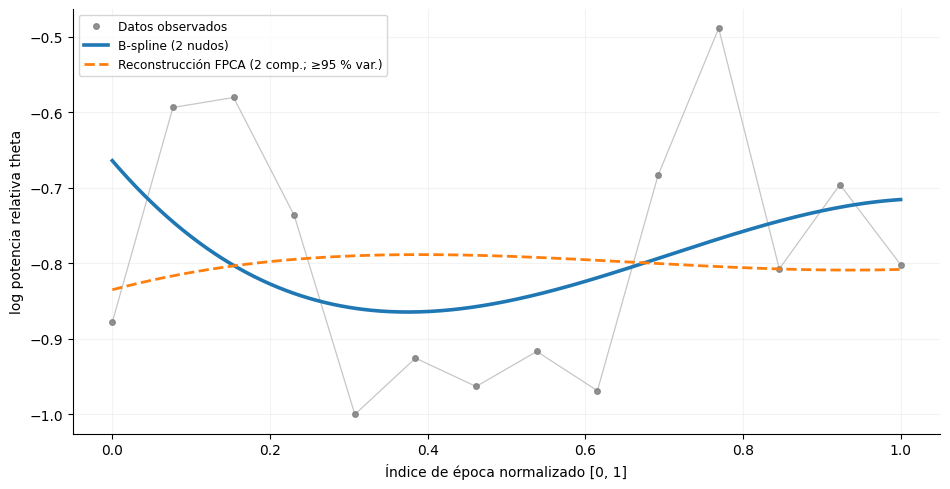

Figura guardada (theta): /content/drive/MyDrive/tesis_parkinson/resultados/02B_enfoque_B/figuras/tesis/reconstruccion_B_theta_Pz.png


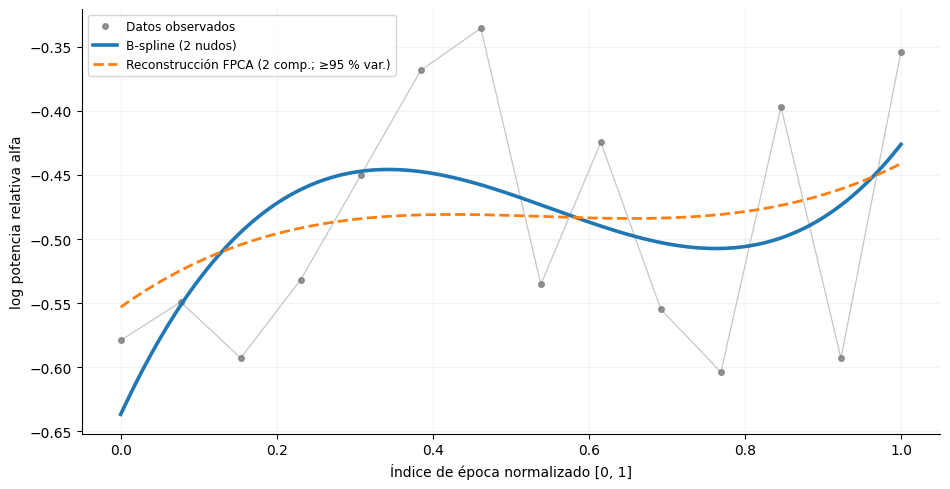

Figura guardada (alfa): /content/drive/MyDrive/tesis_parkinson/resultados/02B_enfoque_B/figuras/tesis/reconstruccion_B_alfa_Pz.png
Sujeto ilustrativo: sub-030 | grupo: HC | canal: Pz | épocas: 14
X_raw y X_chol contienen la misma función en sistemas de coordenadas distintos; X_chol no se representa como una curva adicional.


In [20]:
# ============================================================================
# FIGURAS DE RECONSTRUCCIONES INDEPENDIENTES THETA Y ALFA
# ============================================================================
selected_channel_idx = ch_ref.index(CHANNEL)


def representative_subject_index() -> int:
    """Usa sub-030 si está disponible; en caso contrario, un sujeto mediano."""
    target_subject = 'sub-030'
    for idx, subject in enumerate(per_subj):
        if str(subject['subject_id']).lower() == target_subject:
            return idx

    features = np.asarray([
        [
            per_subj[idx]['power'][band][:, selected_channel_idx].mean()
            for band in BANDS_DEF
        ]
        for idx in range(len(per_subj))
    ], dtype=float)
    target = np.median(features, axis=0)
    scale = features.std(axis=0, ddof=1)
    scale = np.where(scale > EPS, scale, 1.0)
    return int(np.argmin(np.linalg.norm((features - target) / scale, axis=1)))


representative_idx = representative_subject_index()
representative = per_subj[representative_idx]
n_epochs = representative['n_ep']
t_subject = np.linspace(0.0, 1.0, n_epochs)
fine_grid = np.linspace(0.0, 1.0, 301)
subject_group = NAME[int(representative['label'])]

fig_reconstruccion_paths = {}
for band in BANDS_DEF:
    band_info = bases_info[band]
    chol = band_info['L']

    Xchol_selected = Xchol_band[band][:, selected_channel_idx, :]
    illustrative_pca = PCA(n_components=0.95, svd_solver='full')
    scores = illustrative_pca.fit_transform(Xchol_selected)
    Xrec_chol = illustrative_pca.inverse_transform(scores)
    Xrec_raw = linalg.solve_triangular(
        chol.T, Xrec_chol.T, lower=False, check_finite=True,
    ).T

    fine_basis = band_info['sp'].transform(fine_grid.reshape(-1, 1))
    raw_trajectory = representative['power'][band][:, selected_channel_idx]
    bspline_trajectory = (
        fine_basis @ Xraw_band[band][representative_idx, selected_channel_idx, :]
    )
    fpca_trajectory = fine_basis @ Xrec_raw[representative_idx]

    fig, ax = plt.subplots(figsize=(9.6, 5.0))
    ax.plot(t_subject, raw_trajectory, color='0.72', linewidth=0.9, alpha=0.8)
    ax.plot(
        t_subject, raw_trajectory, 'o', markersize=4, color='0.50', alpha=0.85,
        label='Datos observados',
    )
    ax.plot(
        fine_grid, bspline_trajectory, linewidth=2.6,
        label=f'B-spline ({K_OPT_BAND[band]} nudos)',
    )
    ax.plot(
        fine_grid, fpca_trajectory, linewidth=2.0, linestyle='--',
        label=f'Reconstrucción FPCA ({illustrative_pca.n_components_} comp.; ≥95 % var.)',
    )
    ax.set_xlabel('Índice de época normalizado [0, 1]')
    ax.set_ylabel(f'log potencia relativa {BAND_DISPLAY[band]}')
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(alpha=0.15)
    ax.legend(fontsize=8.7, frameon=True, loc='best')
    fig.tight_layout()

    out_path = FIG_TESIS_DIR / f'reconstruccion_B_{BAND_DISPLAY[band]}_{CHANNEL}.png'
    fig.savefig(out_path, dpi=220, bbox_inches='tight')
    plt.show()
    fig_reconstruccion_paths[band] = out_path
    print(f'Figura guardada ({BAND_DISPLAY[band]}):', out_path)

print('Sujeto ilustrativo:', representative['subject_id'], '| grupo:', subject_group,
      '| canal:', CHANNEL, '| épocas:', n_epochs)
print(
    'X_raw y X_chol contienen la misma función en sistemas de coordenadas distintos; '
    'X_chol no se representa como una curva adicional.'
)


## 8. Verificación del archivo generado

Se comprueba la integridad del archivo NPZ, la cohorte, las bandas y las dimensiones,
y que existan las figuras generadas, antes de utilizar el archivo en el modelado.

In [21]:
# ============================================================================
# VERIFICACIÓN DE RECARGA DEL ARCHIVO DEL ENFOQUE B
# ============================================================================
with np.load(DATASET_PATH, allow_pickle=False) as saved:
    required_keys = {
        'X_raw', 'X_chol', 'X_mean_theta_alpha', 'y', 'groups',
        'subject_ids', 'n_epochs', 'channels', 'bands',
        'n_basis_per_band', 'k_por_banda',
    }
    missing_keys = required_keys.difference(saved.files)
    if missing_keys:
        raise AssertionError(f'Faltan claves en el NPZ: {sorted(missing_keys)}')

    assert saved['bands'].tolist() == ['theta', 'alpha']
    assert saved['X_raw'].shape == X_raw.shape
    assert saved['X_chol'].shape == X_chol.shape
    assert saved['X_mean_theta_alpha'].shape == X_mean_theta_alpha.shape
    assert len(np.unique(saved['subject_ids'])) == len(per_subj)
    assert np.isfinite(saved['X_raw']).all()
    assert np.isfinite(saved['X_chol']).all()

expected_figures = [
    FIG_TESIS_DIR / 'gcv_enfoque_B_theta_alfa.png',
    FIG_TESIS_DIR / 'curvas_funcionales_B_theta.png',
    FIG_TESIS_DIR / 'curvas_funcionales_B_alfa.png',
    FIG_TESIS_DIR / f'reconstruccion_B_theta_{CHANNEL}.png',
    FIG_TESIS_DIR / f'reconstruccion_B_alfa_{CHANNEL}.png',
]
for path in expected_figures + [OUT_DIR / 'validacion_cholesky_B.csv']:
    assert path.exists(), f'No se generó {path}'

print('Verificación superada: archivo NPZ y figuras disponibles.')
print('Dataset del Enfoque B para el cuaderno de modelado:', DATASET_PATH)


Verificación superada: archivo NPZ y figuras disponibles.
Dataset del Enfoque B para el cuaderno de modelado: /content/drive/MyDrive/tesis_parkinson/resultados/02B_enfoque_B/enfoque_B_dataset_theta_alpha.npz
